# Validate against buoy observations

Compare **offshore hindcast** (closest goal node), **bulk metamodel**, **spectral metamodel**, and **dynamic SnapWave** to Lauri buoy records.

**Prerequisites**

1. Fitted models — `06_Validate_Metamodel.ipynb` (`mm.fit_all`)
2. Dynamic run for the same period — `08_Dynamic_Cases_Generation.ipynb`
3. Processed buoy pickles under `inputs/LauriBuoys/processed/`

Use the **same `period`** for buoy data, reconstruction, and dynamic output.

In [ ]:
import matplotlib.pyplot as plt
import xarray as xr
from utils.model import metamodel as mm
from utils.evaluation import validation as val
from utils.config import SIMULATIONS, resolve


## Configuration

Map each SnapWave buoy site to a processed pickle. Keys must match mesh site ids
(e.g. `buoy_Apolima_Buoy`). Set `period` to overlap buoy records and dynamic output.

In [ ]:
period = "2020"  # e.g. "1990-05" or "2020-05" — must match buoy + dynamic
offshore_name = "WHACS"
mda_n = 450
pca_variance = {"hs": 0.99, "dir": 0.99}

# Buoy sites to validate (subset of buoy_files keys)
sites = ["buoy_Aunuu_Buoy"]

# SnapWave site id → LauriBuoys processed pickle
buoy_files = {
    "buoy_Apolima_Buoy": (
        "inputs/LauriBuoys/processed/samoaapolima_lon187.8_lat-13.88_year1989_1990.pkl"
    ),
    "buoy_Aunuu_Buoy": "inputs/LauriBuoys/processed/americansita.nc",
}

dynamic_path = (
    resolve(SIMULATIONS["dynamic_cases"]) / f"Dynamic_Cases_{offshore_name}_fullaso.nc"
)

# Buoy pickles may lack direction — compare hs/tp only unless dir is present
variables = ["hs", "tp", "dir"]

print(f"period        : {period}")
print(f"mda_n         : {mda_n}")
print(f"sites         : {sites}")
print(f"dynamic path  : {dynamic_path}")
print(f"dynamic exists: {dynamic_path.is_file()}")

## 1 · Check models

In [ ]:
mm.require_models_all(mda_n, pca_variance=pca_variance)

## 2 · Load buoy observations

In [ ]:
# buoy_files_active = {k: buoy_files[k] for k in sites}
# buoy = val.load_buoy_observations(buoy_files_active, time=period)

buoy = (
    xr.open_dataset("inputs/LauriBuoys/processed/americansita.nc")
    .rename({"dm": "dir"})
    .sel(time=period)
    .expand_dims({"sites": ["buoy_Aunuu_Buoy"]})
    .transpose("time", "sites")
)
buoy

## 3 · Reconstruct metamodel, load dynamic, and closest-goal offshore hindcast

Metamodel bulk/spectral reconstructions, dynamic SnapWave, and bulk offshore forcing
at each buoy's **closest goal hindcast node** (all sources in ``Samoa.json`` —
currently WHACS only).

In [ ]:
bulk = mm.reconstruct(
    period,
    mda_n,
    spectral=False,
    offshore_name=offshore_name,
    sites=sites,
    pca_variance=pca_variance,
)

spectral = mm.reconstruct(
    period,
    mda_n,
    spectral=True,
    offshore_name=offshore_name,
    sites=sites,
    pca_variance=pca_variance,
)

if not dynamic_path.is_file():
    raise FileNotFoundError(
        f"Dynamic output not found: {dynamic_path}\n"
        "Run 08_Dynamic_Cases_Generation for this period or change `period`."
    )

dynamic = xr.open_dataset(dynamic_path).sel(time=period)
site_ids = mm.resolve_reconstruction_sites(dynamic, sites)
dynamic = dynamic.sel(sites=site_ids)[[v for v in variables if v in dynamic]].load()

offshore_hindcast, closest_goals = val.load_offshore_hindcast_at_buoys(
    period,
    sites,
    variables=variables,
)
closest_goals

estimates = {
    **offshore_hindcast,
    "Bulk metamodel": bulk[[v for v in variables if v in bulk]],
    "Spectral metamodel": spectral[[v for v in variables if v in spectral]],
    "Dynamic SnapWave": dynamic,
}

## 4 · Metrics vs buoy

In [11]:
results = val.compare_all(
    buoy,
    estimates,
    sites=sites,
    variables=variables,
    reference_label="Buoy",
)

summary = val.metrics_summary(results)
summary

2026-07-03 13:27:46,233 - Samoa.validation - INFO - Computed 3 validation metric row(s)
2026-07-03 13:27:46,242 - Samoa.validation - INFO - Computed 3 validation metric row(s)
2026-07-03 13:27:46,250 - Samoa.validation - INFO - Computed 3 validation metric row(s)
2026-07-03 13:27:46,259 - Samoa.validation - INFO - Computed 3 validation metric row(s)


,group,site_source,site_label,variable,label,n,bias,rmse,r2,estimate_label,reference_label,model
0,buoy_Aunuu_Buoy,buoy,waves,hs,Hs,8784,-0.207271,0.299210,0.685492,WHACS (closest goal),Buoy,WHACS (closest goal)
1,buoy_Aunuu_Buoy,buoy,waves,tp,Tp,8784,0.622604,2.431575,0.101940,WHACS (closest goal),Buoy,WHACS (closest goal)
2,buoy_Aunuu_Buoy,buoy,waves,dir,Dir,8784,0.092203,29.058883,0.664388,WHACS (closest goal),Buoy,WHACS (closest goal)
3,buoy_Aunuu_Buoy,buoy,waves,hs,Hs,8784,-0.060810,0.231990,0.820283,Bulk metamodel,Buoy,Bulk metamodel
4,buoy_Aunuu_Buoy,buoy,waves,tp,Tp,8784,0.595664,2.493882,0.050235,Bulk metamodel,Buoy,Bulk metamodel
5,buoy_Aunuu_Buoy,buoy,waves,dir,Dir,8784,4.653064,30.586343,0.628178,Bulk metamodel,Buoy,Bulk metamodel
6,buoy_Aunuu_Buoy,buoy,waves,hs,Hs,8784,-0.171629,0.278414,0.776230,Spectral metamodel,Buoy,Spectral metamodel
7,buoy_Aunuu_Buoy,buoy,waves,tp,Tp,8784,-0.487039,2.093079,0.320265,Spectral metamodel,Buoy,Spectral metamodel
8,buoy_Aunuu_Buoy,buoy,waves,dir,Dir,8784,6.053682,41.265976,0.323195,Spectral metamodel,Buoy,Spectral metamodel
9,buoy_Aunuu_Buoy,buoy,waves,hs,Hs,8784,-0.242843,0.319930,0.602491,Dynamic SnapWave,Buoy,Dynamic SnapWave


## 5 · Scatter plots

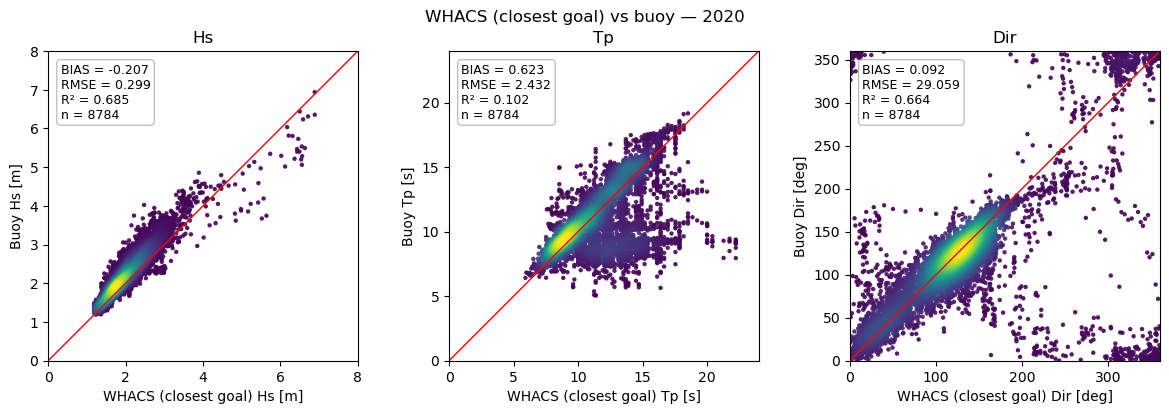

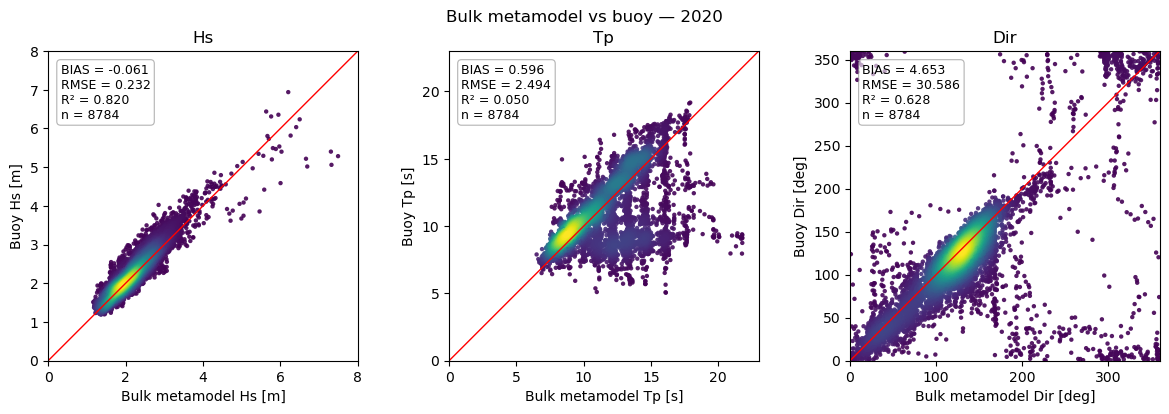

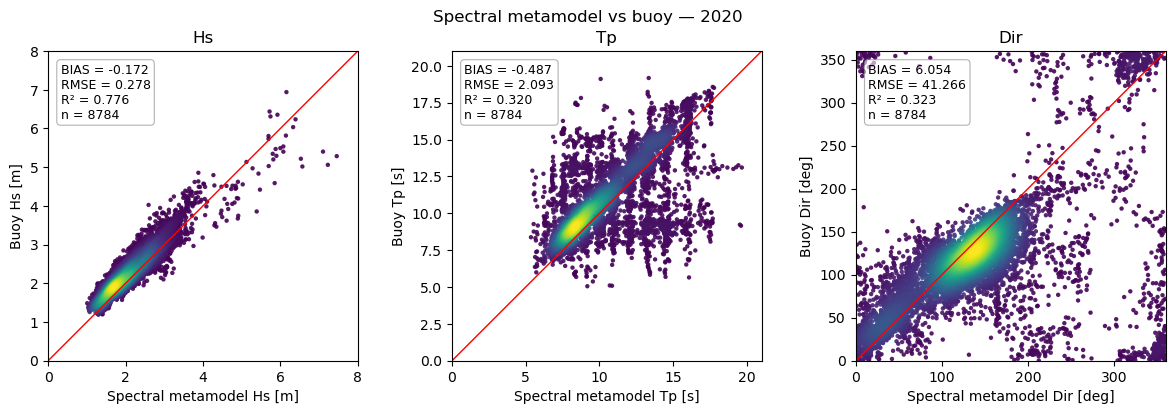

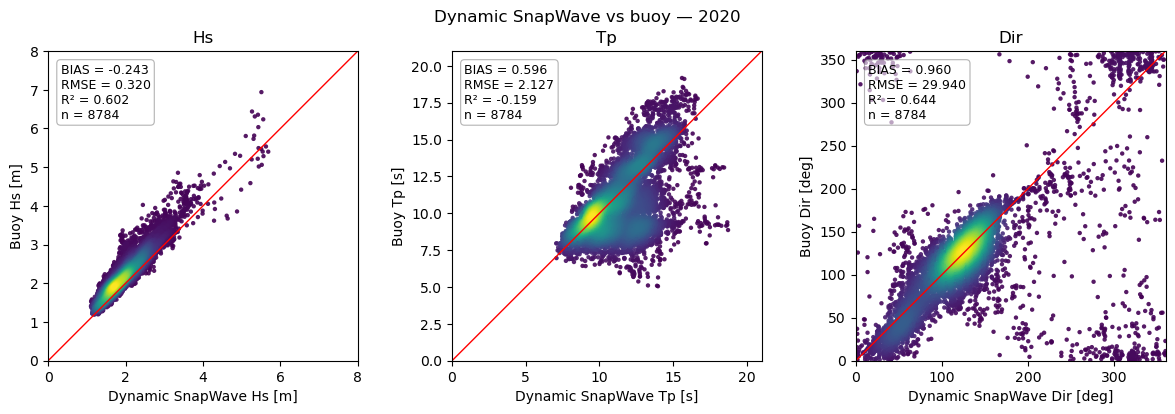

In [12]:
group = mm.resolve_sites(estimates["Bulk metamodel"], sites)[0]

for name, result in results.items():
    result.plot_scatter(
        group,
        variables=variables,
        estimate_label=name,
        reference_label="Buoy",
    )
    plt.suptitle(f"{name} vs buoy — {period}")
    plt.show()

## 6 · Time series

Line plots of buoy observations vs each model over the validation period (direction as scatter).

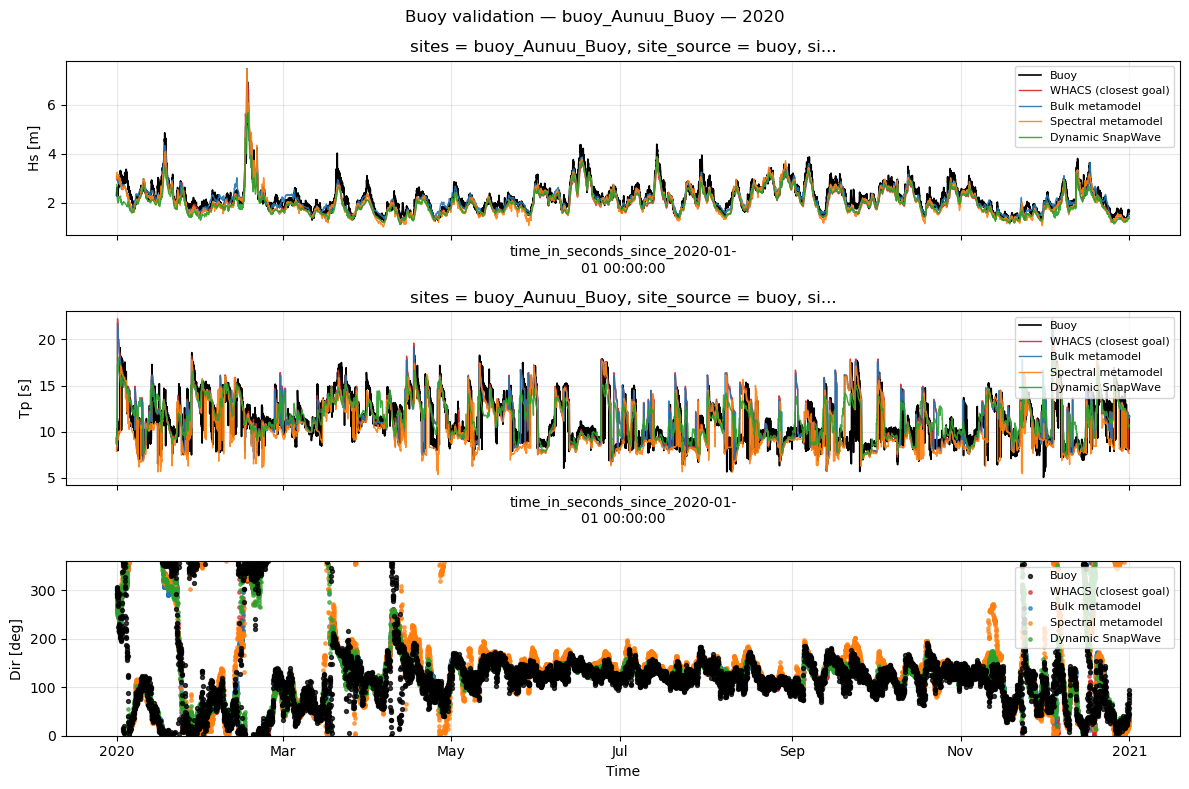

In [13]:
for site in sites:
    val.plot_buoy_timeseries(buoy, estimates, site, variables=variables)
    plt.suptitle(f"Buoy validation — {site} — {period}")
    plt.show()